# StockSense AI: guarded Colab training workflow

This notebook reuses the repository's canonical `stationary-return-v1` training and artifact smoke-test code. It does not train, refresh market data, or export files by default. Set the flags in the next cell deliberately.

**Do not promote a candidate model based on the training validation metrics alone.** This workflow checks that artifacts reload and run; it does not replace a separate untouched walk-forward performance evaluation. Candidate outputs are written outside `models_storage_stationary/` so they cannot silently overwrite the current packages.

Colab is optional for running the existing inference service. Use it for a reproducible training session or if local compute/dependencies are inconvenient—not because training has not happened.

In [ ]:
import sys
import tensorflow as tf

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
!nvidia-smi

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Sun Oct 11 09:33:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   56C    P8             11W /   70W |       3MiB /  15360MiB |      0%     

In [ ]:
!git clone https://github.com/manojsai7/Stock_SenseAi
%cd Stock_SenseAi

Cloning into 'Stock_SenseAi'...
remote: Enumerating objects: 342, done.
remote: Counting objects: 100% (342/342), done.
remote: Compressing objects: 100% (266/266), done.
remote: Total 342 (delta 66), reused 341 (delta 65), pack-reused 0 (from 0)
Receiving objects: 100% (342/342), 7.59 MiB | 19.10 MiB/s, done.
Resolving deltas: 100% (66/66), done.
/content/Stock_SenseAi


In [ ]:
!git status

On branch master
Your branch is up to date with 'origin/master'.

nothing to commit, working tree clean


In [ ]:
import sys
import tensorflow as tf
import keras
import numpy
import pandas
import sklearn

print("Python:", sys.version)
print("TF:", tf.__version__)
print("Keras:", keras.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Sklearn:", sklearn.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
TF: 2.21.0
Keras: 3.13.2
NumPy: 2.1.3
Pandas: 2.2.3
Sklearn: 1.6.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Pinning Environment to Match Local Setup

It appears there are some differences between the current Colab environment and your local setup for key libraries. To ensure consistency and reproducibility, I will install the exact versions of TensorFlow, Keras, NumPy, Pandas, and Scikit-learn that you specified.

**Note:** After executing the next cell, you will need to **restart the runtime** for the new package versions to take effect. You can do this by navigating to `Runtime > Restart runtime...` in the Colab menu.

In [ ]:
# Install specific versions of libraries to match local environment
!pip install tensorflow==2.20.0 keras==3.11.2 numpy==2.2.4 pandas==2.2.3 scikit-learn==1.6.1 --force-reinstall

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 6.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 9.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.8/620.8 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 67.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 87.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 101.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 88.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 121.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/

### Verification Step (After Runtime Restart)

After restarting the runtime as instructed above, please run the following cell to verify that the installed library versions now match your local environment.

In [ ]:
!git clone https://github.com/manojsai7/Stock_SenseAi
%cd Stock_SenseAi

fatal: destination path 'Stock_SenseAi' already exists and is not an empty directory.
/content/Stock_SenseAi


In [ ]:
!git status

On branch master
Your branch is up to date with 'origin/master'.

nothing to commit, working tree clean


In [ ]:
import numpy as np

stock = "RELIANCE_NS"

base = f"data/sequences/{stock}"

X_train = np.load(f"{base}/X_train.npy")
y_train = np.load(f"{base}/y_train.npy")
X_val   = np.load(f"{base}/X_val.npy")
y_val   = np.load(f"{base}/y_val.npy")
X_test  = np.load(f"{base}/X_test.npy")
y_test  = np.load(f"{base}/y_test.npy")

print("Train:", X_train.shape, y_train.shape)
print("Val  :", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (825, 30, 6) (825,)
Val  : (183, 30, 6) (183,)
Test : (184, 30, 6) (184,)


In [ ]:
print(X_train[0])
print("Shape:", X_train[0].shape)
print("Target:", y_train[0])

[[0.22247262 0.22503506 0.2469063  0.23476382 0.02080141 0.31310657]
 [0.24338005 0.23696212 0.22014472 0.23720929 0.24802305 0.3099172 ]
 [0.23199771 0.24399191 0.24455667 0.25278923 0.19125661 0.3031469 ]
 [0.24124597 0.2669773  0.25777808 0.27503496 0.12504667 0.2984953 ]
 [0.25970298 0.2768506  0.28318545 0.27870318 0.13076647 0.29336834]
 [0.27776486 0.29916474 0.30026975 0.30911353 0.10625175 0.28875747]
 [0.3070905  0.30188978 0.3106239  0.2970441  0.05857849 0.28320724]
 [0.28499737 0.2804051  0.25088865 0.24979162 0.138268   0.2746193 ]
 [0.22721541 0.22033523 0.22380853 0.20727217 0.12441932 0.26249343]
 [0.19642723 0.212476   0.21508709 0.21460842 0.10373074 0.25221235]
 [0.17753553 0.1808811  0.1361966  0.12818924 0.2942091  0.24049844]
 [0.09607937 0.14316462 0.10274489 0.14562288 0.30887657 0.22956319]
 [0.1331912  0.14999698 0.13026299 0.11844695 0.2051327  0.21822731]
 [0.12765808 0.22274438 0.14109495 0.23010947 0.51711476 0.21061723]
 [0.2025928  0.20347142 0.17641848

STARting building!

In [ ]:
from ml.models.cnn_lstm import build_cnn_lstm_model

model = build_cnn_lstm_model((30, 6))

model.summary()

Model: "TensorFlow_CNN_LSTM_Stock_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 30, 64)         │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool1d (MaxPooling1D)        │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 50)             │        23,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_proj (Dense)              │ (None, 32)             │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_relu (LeakyReLU)          │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_output (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,881 (101.10 KB)

 Trainable params: 25,881 (101.10 KB)

 Non-trainable params: 0 (0.00 B)

step 9

In [ ]:
history = model.fit(
    X_train[:128],
    y_train[:128],
    validation_data=(X_val[:32], y_val[:32]),
    epochs=1,
    batch_size=32,
    verbose=1
)

4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 113ms/step - loss: 0.0235 - mae: 0.1233 - mse: 0.0235 - val_loss: 0.0095 - val_mae: 0.0760 - val_mse: 0.0095


10 step

In [ ]:
import tensorflow as tf
import numpy as np

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

for name, arr in [
    ("X_train", X_train),
    ("y_train", y_train),
    ("X_val", X_val),
    ("y_val", y_val),
    ("X_test", X_test),
    ("y_test", y_test),
]:
    print(name, arr.shape, arr.dtype, "finite:", np.isfinite(arr).all())

TensorFlow: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
X_train (825, 30, 6) float32 finite: True
y_train (825,) float32 finite: True
X_val (183, 30, 6) float32 finite: True
y_val (183,) float32 finite: True
X_test (184, 30, 6) float32 finite: True
y_test (184,) float32 finite: True


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


Step 12 — Train the full RELIANCE CNN-LSTM

In [ ]:
from pathlib import Path
from datetime import datetime
import json
import platform
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from ml.models.cnn_lstm import build_cnn_lstm_model

# 1. Make target shape match model output: (N, 1)
X_train = X_train.astype("float32")
X_val = X_val.astype("float32")

y_train = y_train.reshape(-1, 1).astype("float32")
y_val = y_val.reshape(-1, 1).astype("float32")

assert X_train.shape[1:] == (30, 6)
assert X_val.shape[1:] == (30, 6)
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)

assert all(
    np.isfinite(a).all()
    for a in [X_train, y_train, X_val, y_val]
)

# 2. Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# 3. Create a unique, persistent experiment directory
run_id = "RELIANCE_CNNLSTM_W30_" + datetime.now().strftime("%Y%m%d_%H%M%S")
run_dir = Path("/content/drive/MyDrive/StockSenseAI/experiments/runs") / run_id
run_dir.mkdir(parents=True, exist_ok=False)

checkpoint_path = run_dir / "best_cnn_lstm.keras"
history_path = run_dir / "training_history.csv"

# 4. Build a fresh model
model = build_cnn_lstm_model((30, 6))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"],
)

model.summary()

# 5. Store the experiment configuration
config = {
    "symbol": "RELIANCE.NS",
    "architecture": "CNN-LSTM",
    "window_size": 30,
    "features": ["Open", "High", "Low", "Close", "Volume", "MA20"],
    "target": "Close(t+1)",
    "filters": 64,
    "kernel_size": 3,
    "pool_size": 2,
    "lstm_units": 50,
    "batch_size": 32,
    "maximum_epochs": 50,
    "learning_rate": 0.001,
    "loss": "MSE",
    "seed": SEED,
    "python_version": platform.python_version(),
    "tensorflow_version": tf.__version__,
    "gpu_devices": [str(d) for d in tf.config.list_physical_devices("GPU")],
    "train_samples": len(X_train),
    "validation_samples": len(X_val),
}

with open(run_dir / "config.json", "w") as f:
    json.dump(config, f, indent=2)

# 6. Training callbacks
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1,
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=10,
        restore_best_weights=True,
        verbose=1,
    ),
    tf.keras.callbacks.CSVLogger(
        filename=str(history_path),
        append=False,
    ),
    tf.keras.callbacks.TerminateOnNaN(),
]

# 7. FULL training run: not the 128-sample smoke test
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    shuffle=False,
    callbacks=callbacks,
    verbose=1,
)

print("\nTraining completed.")
print("Run directory:", run_dir)
print("Best validation loss:", min(history.history["val_loss"]))
print("Best epoch:", 1 + history.history["val_loss"].index(
    min(history.history["val_loss"])
))
print("Best checkpoint exists:", checkpoint_path.exists())
print("History exists:", history_path.exists())

Model: "TensorFlow_CNN_LSTM_Stock_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 30, 64)         │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool1d (MaxPooling1D)        │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 50)             │        23,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_proj (Dense)              │ (None, 32)             │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_relu (LeakyReLU)          │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_output (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,881 (101.10 KB)

 Trainable params: 25,881 (101.10 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0185 - mae: 0.1113
Epoch 1: val_loss improved from None to 0.01924, saving model to /content/drive/MyDrive/StockSenseAI/experiments/runs/RELIANCE_CNNLSTM_W30_20261011_094448/best_cnn_lstm.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - loss: 0.0195 - mae: 0.1113 - val_loss: 0.0192 - val_mae: 0.1229
Epoch 2/50
25/26 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0113 - mae: 0.0831
Epoch 2: val_loss improved from 0.01924 to 0.00935, saving model to /content/drive/MyDrive/StockSenseAI/experiments/runs/RELIANCE_CNNLSTM_W30_20261011_094448/best_cnn_lstm.keras
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0224 - mae: 0.1199 - val_loss: 0.0094 - val_mae: 0.0795
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0170 - mae: 0.1054
Epoch 3: val_loss did not improve from 0.00935
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0189 - mae: 0.1108 - val_loss: 0.0100 - val_mae: 0.0851
Epoch 4/50
19/26 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/

,epoch,loss,mae,val_loss,val_mae
40,40,0.002465,0.037693,0.001620,0.030806
41,41,0.002847,0.041465,0.001132,0.025349
42,42,0.003287,0.044237,0.001157,0.025309
43,43,0.003211,0.043549,0.001364,0.028744
44,44,0.003252,0.043008,0.001626,0.032334
45,45,0.002925,0.041886,0.001549,0.031123
46,46,0.002421,0.038440,0.001161,0.025250
47,47,0.002173,0.035868,0.001136,0.024821
48,48,0.002469,0.036871,0.001333,0.027322
49,49,0.002397,0.037080,0.001138,0.025436


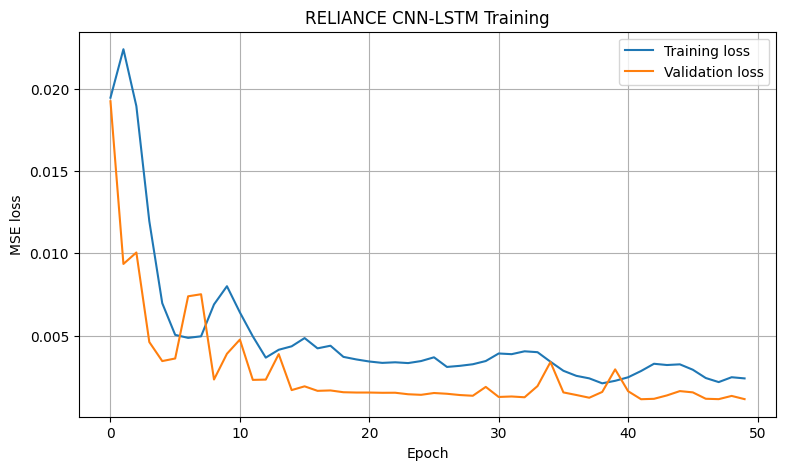

In [ ]:
hist = pd.read_csv(history_path)

display(hist.tail(10))

plt.figure(figsize=(9, 5))
plt.plot(hist["epoch"], hist["loss"], label="Training loss")
plt.plot(hist["epoch"], hist["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("RELIANCE CNN-LSTM Training")
plt.legend()
plt.grid(True)
plt.show()

#new

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

# Find experiment runs in the cloned repo or Google Drive
search_roots = [
    Path.cwd() / "experiments" / "runs",
    Path.cwd() / "runs",
    Path("/content/drive/MyDrive/StockSenseAI/experiments/runs"),
    Path("/content/drive/MyDrive/Stock_SenseAi/experiments/runs"),
]

run_dirs = []
for root in search_roots:
    if root.exists():
        run_dirs.extend(
            p.parent for p in root.rglob("metrics.json")
        )

# Remove duplicates and prefer the most recently modified run
run_dirs = list(set(run_dirs))

if not run_dirs:
    print("No metrics.json found.")
    print("Current directory:", Path.cwd())
    print("Please check where the runs folder is stored.")
else:
    run_dir = max(
        run_dirs,
        key=lambda p: (p / "metrics.json").stat().st_mtime
    )

    print("SELECTED RUN:", run_dir)

    # 1. Reported experiment metrics
    metrics_file = run_dir / "metrics.json"
    print("\n========== METRICS.JSON ==========")
    print(json.dumps(
        json.loads(metrics_file.read_text()),
        indent=2
    ))

    # 2. Training and validation history
    history_file = run_dir / "training_history.csv"

    if history_file.exists():
        history = pd.read_csv(history_file)
        print("\n========== TRAINING HISTORY ==========")
        print(history.tail(10).to_string(index=False))

        if "val_loss" in history.columns:
            best_idx = history["val_loss"].idxmin()
            print("\nBest validation epoch:", int(best_idx) + 1)
            print("Best validation loss:",
                  float(history.loc[best_idx, "val_loss"]))

    # 3. Saved historical test predictions
    prediction_files = list(
        run_dir.glob("*actual_vs_predicted*.csv")
    )

    if prediction_files:
        pred_df = pd.read_csv(prediction_files[0])

        print("\n========== TEST PREDICTIONS ==========")
        print("Columns:", pred_df.columns.tolist())
        print(pred_df.head(5).to_string(index=False))

        # Support common column names
        col_lookup = {
            str(c).lower(): c for c in pred_df.columns
        }

        actual_names = [
            "actual_close", "actual", "y_true",
            "actual_price", "target_close"
        ]
        predicted_names = [
            "predicted_close", "predicted", "y_pred",
            "predicted_price"
        ]

        actual_col = next(
            (col_lookup[c] for c in actual_names
             if c in col_lookup), None
        )
        predicted_col = next(
            (col_lookup[c] for c in predicted_names
             if c in col_lookup), None
        )

        if actual_col and predicted_col:
            actual = pd.to_numeric(
                pred_df[actual_col], errors="coerce"
            ).to_numpy(dtype=float)

            predicted = pd.to_numeric(
                pred_df[predicted_col], errors="coerce"
            ).to_numpy(dtype=float)

            valid = (
                np.isfinite(actual)
                & np.isfinite(predicted)
            )
            actual, predicted = actual[valid], predicted[valid]

            error = predicted - actual
            mae = np.mean(np.abs(error))
            rmse = np.sqrt(np.mean(error**2))

            nonzero = actual != 0
            mape = (
                np.mean(
                    np.abs(error[nonzero] / actual[nonzero])
                ) * 100
                if nonzero.any() else float("nan")
            )

            print("\n========== RECALCULATED TEST METRICS ==========")
            print("Valid samples:", len(actual))
            print(f"MAE:  {mae:.4f}")
            print(f"RMSE: {rmse:.4f}")
            print(f"MAPE: {mape:.4f}%")

            if "direction_correct" in pred_df.columns:
                correct = pred_df.loc[
                    valid, "direction_correct"
                ].astype(bool)
                print(
                    "Directional Accuracy:",
                    f"{correct.mean() * 100:.2f}%"
                )
        else:
            print(
                "Couldn't identify the actual/predicted columns "
                "automatically. Use the printed column names."
            )
    else:
        print("No actual_vs_predicted CSV found in this run.")

SELECTED RUN: /content/Stock_SenseAi/experiments/runs/run_RELIANCE_NS_20261007_120035

========== METRICS.JSON ==========
{
  "symbol": "RELIANCE.NS",
  "run_id": "run_RELIANCE_NS_20261007_120035",
  "epochs": 5,
  "naive_persistence": {
    "mae": 14.16,
    "rmse": 18.52,
    "mape": 1.06,
    "directional_accuracy": 48.37
  },
  "pure_lstm": {
    "mae": 26.39,
    "rmse": 33.32,
    "mape": 1.95,
    "directional_accuracy": 50.0
  },
  "cnn_lstm": {
    "mae": 30.87,
    "rmse": 38.31,
    "mape": 2.33,
    "directional_accuracy": 51.09
  }
}

========== TRAINING HISTORY ==========
 epoch     loss      mae      mse  val_loss  val_mae  val_mse
     0 0.023564 0.124572 0.023564  0.006362 0.065930 0.006362
     1 0.018353 0.106872 0.018353  0.008929 0.078157 0.008929
     2 0.013870 0.094580 0.013870  0.006204 0.062974 0.006204
     3 0.008221 0.070527 0.008221  0.003467 0.046507 0.003467
     4 0.006050 0.059882 0.006050  0.005670 0.061301 0.005670

Best validation epoch: 4
Best vali

In [ ]:
from pathlib import Path
import json

roots = [
    Path("/content/Stock_SenseAi/experiments/runs"),
    Path("/content/drive/MyDrive/StockSenseAI/experiments/runs"),
    Path("/content/drive/MyDrive/Stock_SenseAi/experiments/runs"),
]

found = {}

for root in roots:
    if not root.exists():
        print("Not found:", root)
        continue

    for file in root.rglob("metrics.json"):
        found[str(file)] = file

print("\n========== AVAILABLE EXPERIMENT RUNS ==========")

for path in sorted(
    found.values(),
    key=lambda p: p.stat().st_mtime,
    reverse=True
):
    run_dir = path.parent

    try:
        metrics = json.loads(path.read_text())
    except Exception as exc:
        print("Could not read:", path, exc)
        continue

    print("\nRun:", run_dir.name)
    print("Path:", run_dir)
    print("Modified:", path.stat().st_mtime)
    print("Epochs:", metrics.get("epochs"))

    for model_name in ("naive_persistence", "pure_lstm", "cnn_lstm"):
        if model_name in metrics:
            print(f"  {model_name}: {metrics[model_name]}")

Not found: /content/drive/MyDrive/Stock_SenseAi/experiments/runs

========== AVAILABLE EXPERIMENT RUNS ==========

Run: run_RELIANCE_NS_20261007_120035
Path: /content/Stock_SenseAi/experiments/runs/run_RELIANCE_NS_20261007_120035
Modified: 1791711217.3802671
Epochs: 5
  naive_persistence: {'mae': 14.16, 'rmse': 18.52, 'mape': 1.06, 'directional_accuracy': 48.37}
  pure_lstm: {'mae': 26.39, 'rmse': 33.32, 'mape': 1.95, 'directional_accuracy': 50.0}
  cnn_lstm: {'mae': 30.87, 'rmse': 38.31, 'mape': 2.33, 'directional_accuracy': 51.09}


In [ ]:
import pandas as pd
import numpy as np

# Set this to the actual_vs_predicted.csv from the run being inspected.
csv_path = (
    "/content/Stock_SenseAi/experiments/runs/"
    "run_RELIANCE_NS_20261007_120035/"
    "actual_vs_predicted.csv"
)

df = pd.read_csv(csv_path)

print(df[
    [
        "date",
        "actual_close",
        "predicted_close",
        "previous_close",
        "direction_actual",
        "direction_predicted",
        "direction_correct",
    ]
].head(10).to_string(index=False))

actual_delta = df["actual_close"] - df["previous_close"]
pred_delta = df["predicted_close"] - df["previous_close"]

def direction(delta):
    return np.select(
        [delta > 1e-8, delta < -1e-8],
        ["UP", "DOWN"],
        default="FLAT"
    )

df["actual_direction_recomputed"] = direction(actual_delta)
df["predicted_direction_recomputed"] = direction(pred_delta)

print("\nDirection mismatches in saved labels:")
print(
    "Actual:",
    (df["actual_direction_recomputed"] != df["direction_actual"]).sum()
)
print(
    "Predicted:",
    (df["predicted_direction_recomputed"] != df["direction_predicted"]).sum()
)

print("\nRows requiring inspection:")
print(
    df.loc[
        (df["actual_direction_recomputed"] != df["direction_actual"])
        | (df["predicted_direction_recomputed"] != df["direction_predicted"]),
        [
            "date",
            "actual_close",
            "previous_close",
            "direction_actual",
            "actual_direction_recomputed",
        ]
    ].head(10).to_string(index=False)
)

      date  actual_close  predicted_close  previous_close direction_actual direction_predicted  direction_correct
2026-01-14        1458.8          1507.11          1458.8               UP                  UP               True
2026-01-15        1457.9          1502.23          1458.8             DOWN                  UP              False
2026-01-16        1413.6          1497.96          1457.9             DOWN                  UP              False
2026-01-19        1394.0          1488.33          1413.6             DOWN                  UP              False
2026-01-20        1404.6          1475.28          1394.0               UP                  UP               True
2026-01-21        1402.5          1466.97          1404.6             DOWN                  UP              False
2026-01-22        1386.1          1459.90          1402.5             DOWN                  UP              False
2026-01-23        1380.5          1452.70          1386.1             DOWN              

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

run_dir = Path(
    "/content/Stock_SenseAi/experiments/runs/"
    "run_RELIANCE_NS_20261007_120035"
)

df = pd.read_csv(run_dir / "actual_vs_predicted.csv")

actual_delta = (
    df["actual_close"] - df["previous_close"]
).to_numpy()

predicted_delta = (
    df["predicted_close"] - df["previous_close"]
).to_numpy()

def classify_direction(delta):
    return np.where(
        delta > 1e-8, "UP",
        np.where(delta < -1e-8, "DOWN", "FLAT")
    )

actual_direction = classify_direction(actual_delta)
predicted_direction = classify_direction(predicted_delta)

correct = actual_direction == predicted_direction
accuracy = correct.mean() * 100

print("Samples:", len(df))
print(f"Correct directions: {correct.sum()}/{len(df)}")
print(f"Corrected directional accuracy: {accuracy:.2f}%")

df["actual_direction_corrected"] = actual_direction
df["predicted_direction_corrected"] = predicted_direction
df["direction_corrected"] = correct

print("\nRows previously labelled incorrectly:")
print(
    df.loc[
        df["direction_actual"] != df["actual_direction_corrected"],
        [
            "date",
            "actual_close",
            "previous_close",
            "direction_actual",
            "actual_direction_corrected",
            "predicted_direction_corrected",
            "direction_corrected",
        ]
    ].to_string(index=False)
)

Samples: 184
Correct directions: 89/184
Corrected directional accuracy: 48.37%

Rows previously labelled incorrectly:
      date  actual_close  previous_close direction_actual actual_direction_corrected predicted_direction_corrected  direction_corrected
2026-01-14        1458.8          1458.8               UP                       FLAT                            UP                False
2026-04-30        1430.8          1430.8               UP                       FLAT                          DOWN                False
2026-05-27        1350.5          1350.5               UP                       FLAT                            UP                False
2026-06-25        1318.1          1318.1               UP                       FLAT                            UP                False
2026-09-11        1257.5          1257.5               UP                       FLAT                            UP                False
2026-10-01        1167.7          1167.7               UP         

In [ ]:
raw_path = Path("/content/Stock_SenseAi/data/raw/RELIANCE.NS.csv")
raw = pd.read_csv(raw_path)

print("Raw columns:", raw.columns.tolist())

date_col = next(
    (c for c in raw.columns
     if str(c).strip().lower() in {"date", "datetime"}),
    None
)
close_col = next(
    (c for c in raw.columns
     if str(c).strip().lower() == "close"),
    None
)

if date_col is None or close_col is None:
    print("Could not automatically identify Date/Close columns.")
else:
    hist = raw[[date_col, close_col]].copy()
    hist.columns = ["date", "close"]
    hist["date"] = pd.to_datetime(hist["date"]).dt.date
    hist["close"] = pd.to_numeric(hist["close"], errors="coerce")
    hist = (
        hist.dropna()
        .drop_duplicates("date")
        .sort_values("date")
        .reset_index(drop=True)
    )

    hist["expected_previous_close"] = hist["close"].shift(1)

    check = df.copy()
    check["date"] = pd.to_datetime(check["date"]).dt.date

    check = check.merge(
        hist[["date", "close", "expected_previous_close"]],
        on="date",
        how="left"
    )

    check["actual_matches_history"] = np.isclose(
        check["actual_close"], check["close"], atol=0.02
    )
    check["previous_matches_history"] = np.isclose(
        check["previous_close"],
        check["expected_previous_close"],
        atol=0.02
    )

    print(check[
        [
            "date",
            "actual_close",
            "close",
            "previous_close",
            "expected_previous_close",
            "actual_matches_history",
            "previous_matches_history",
        ]
    ].head(15).to_string(index=False))

    print("\nActual-close mismatches:",
          (~check["actual_matches_history"]).sum())
    print("Previous-close mismatches:",
          (~check["previous_matches_history"]).sum())

Raw columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']
      date  actual_close       close  previous_close  expected_previous_close  actual_matches_history  previous_matches_history
2026-01-14        1458.8 1458.800049          1458.8              1452.800049                    True                     False
2026-01-15        1457.9 1458.800049          1458.8              1458.800049                   False                      True
2026-01-16        1413.6 1457.900024          1457.9              1458.800049                   False                     False
2026-01-19        1394.0 1413.599976          1413.6              1457.900024                   False                     False
2026-01-20        1404.6 1394.000000          1394.0              1413.599976                   False                     False
2026-01-21        1402.5 1404.599976          1404.6              1394.000000                   False                     False
2026-01-22        1386.1 1402.500000    

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import shutil
from pathlib import Path

source = Path(
    "/content/Stock_SenseAi/experiments/runs/"
    "run_RELIANCE_NS_20261007_120035"
)

destination = Path(
    "/content/drive/MyDrive/StockSenseAI/experiments/runs/"
    "run_RELIANCE_NS_20261007_120035"
)

destination.parent.mkdir(parents=True, exist_ok=True)

if not destination.exists():
    shutil.copytree(source, destination)
    print("Experiment backed up to:", destination)
else:
    print("Destination already exists; not overwriting:", destination)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Destination already exists; not overwriting: /content/drive/MyDrive/StockSenseAI/experiments/runs/run_RELIANCE_NS_20261007_120035


In [ ]:
!git status --short
!git diff --stat

fatal: not a git repository (or any of the parent directories): .git
usage: git diff --no-index [<options>] <path> <path>

Diff output format options
    -p, --patch           generate patch
    -s, --no-patch        suppress diff output
    -u                    generate patch
    -U, --unified[=<n>]   generate diffs with <n> lines context
    -W, --[no-]function-context
                          generate diffs with <n> lines context
    --raw                 generate the diff in raw format
    --patch-with-raw      synonym for '-p --raw'
    --patch-with-stat     synonym for '-p --stat'
    --numstat             machine friendly --stat
    --shortstat           output only the last line of --stat
    -X, --dirstat[=<param1,param2>...]
                          output the distribution of relative amount of changes for each sub-directory
    --cumulative          synonym for --dirstat=cumulative
    --dirstat-by-file[=<param1,param2>...]
                          synonym for --dirstat=

In [ ]:
import sys
import tensorflow as tf
import keras
import numpy as np
import pandas as pd
import sklearn

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

print("\nGPU devices:")
print(tf.config.list_physical_devices("GPU"))

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
TensorFlow: 2.21.0
Keras: 3.13.2
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-learn: 1.6.1

GPU devices:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from pathlib import Path
import subprocess

repo = Path("/content/Stock_SenseAi")
url = "https://github.com/manojsai7/Stock_SenseAi.git"

if not (repo / ".git").exists():
    subprocess.run(["git", "clone", url, str(repo)], check=True)
else:
    print("Existing repository found; preserving it.")

subprocess.run(
    ["git", "-C", str(repo), "fetch", "origin"],
    check=True
)

print("\n========== GIT STATUS ==========")
subprocess.run(
    ["git", "-C", str(repo), "status", "-sb"],
    check=True
)

print("\n========== CURRENT COMMIT ==========")
subprocess.run(
    ["git", "-C", str(repo), "log", "-1", "--oneline"],
    check=True
)

print("\n========== CORRECTION MARKERS ==========")

checks = {
    "ml/evaluation/metrics.py": ["compute_direction_signs"],
    "ml/training/experiment_lab.py": ["get_test_target_dates"],
}

for filename, markers in checks.items():
    path = repo / filename
    print(f"\n{filename}:")
    if not path.exists():
        print("FILE MISSING")
        continue

    content = path.read_text(encoding="utf-8")
    for marker in markers:
        print(f"  {marker}: {marker in content}")


========== GIT STATUS ==========

========== CURRENT COMMIT ==========

========== CORRECTION MARKERS ==========

ml/evaluation/metrics.py:
  compute_direction_signs: True

ml/training/experiment_lab.py:
  get_test_target_dates: True


In [ ]:
%cd /content/Stock_SenseAi

from pathlib import Path
import numpy as np

base = Path("data/sequences/RELIANCE_NS")

required_files = [
    "sequences.npz",
    "scaler.pkl",
    "metadata.json",
]

for name in required_files:
    p = base / name
    print(name, "EXISTS" if p.exists() else "MISSING")

if (base / "sequences.npz").exists():
    data = np.load(base / "sequences.npz")

    for name in [
        "X_train", "y_train",
        "X_val", "y_val",
        "X_test", "y_test",
        "dates_test", "actual_target_test", "prev_close_test"
    ]:
        if name in data:
            print(name, data[name].shape)

/content/Stock_SenseAi
sequences.npz EXISTS
scaler.pkl EXISTS
metadata.json EXISTS
X_train (825, 30, 6)
y_train (825,)
X_val (183, 30, 6)
y_val (183,)
X_test (184, 30, 6)
y_test (184,)
dates_test (184,)
actual_target_test (184,)
prev_close_test (184,)


In [ ]:
%cd /content/Stock_SenseAi

!git fetch origin
!git pull --ff-only origin master

/content/Stock_SenseAi
From https://github.com/manojsai7/Stock_SenseAi
 * branch            master     -> FETCH_HEAD
Already up to date.


In [ ]:
from pathlib import Path

checks = {
    "ml/evaluation/metrics.py": ["compute_direction_signs"],
    "ml/training/experiment_lab.py": [
        "get_test_target_dates",
        "recompute_from_existing_run",
    ],
}

for filename, markers in checks.items():
    content = Path(filename).read_text(encoding="utf-8")
    for marker in markers:
        print(f"{filename} | {marker}: {marker in content}")

ml/evaluation/metrics.py | compute_direction_signs: True
ml/training/experiment_lab.py | get_test_target_dates: True
ml/training/experiment_lab.py | recompute_from_existing_run: True


In [ ]:
!python -m pytest tests/ -q

......FF..................................................               [100%]
=================================== FAILURES ===================================
____________________________ test_history_endpoint _____________________________

    def test_history_endpoint():
        response = client.get("/api/stocks/RELIANCE.NS/history?period=1mo")
>       assert response.status_code == 200
E       assert 400 == 200
E        +  where 400 = <Response [400 Bad Request]>.status_code

tests/test_api_endpoints.py:66: AssertionError
------------------------------ Captured log call -------------------------------
ERROR    yfinance:base.py:191 Failed to get ticker 'RELIANCE.NS' reason: Impersonating chrome150 is not supported
ERROR    ml.data.providers.yahoo_provider:yahoo_provider.py:67 Error fetching historical data for RELIANCE.NS: Impersonating chrome150 is not supported
________________________ test_predict_endpoint_contract ________________________

    def test_predict_endpoint_contrac

In [ ]:
%cd /content/Stock_SenseAi

import yfinance as yf
print("Current yfinance:", yf.__version__)

/content/Stock_SenseAi
Current yfinance: 0.2.66


In [ ]:
!pip show yfinance curl_cffi

Name: yfinance
Version: 0.2.66
Summary: Download market data from Yahoo! Finance API
Home-page: https://github.com/ranaroussi/yfinance
Author: Ran Aroussi
Author-email: ran@aroussi.com
License: Apache
Location: /usr/local/lib/python3.13/dist-packages
Requires: beautifulsoup4, curl_cffi, frozendict, multitasking, numpy, pandas, peewee, platformdirs, protobuf, pytz, requests, websockets
Required-by: 
---
Name: curl_cffi
Version: 0.16.3
Summary: libcurl ffi bindings for Python, with impersonation support.
Home-page: 
Author: 
Author-email: lexiforest <infinitesheldon@gmail.com>
License: 
Location: /usr/local/lib/python3.13/dist-packages
Requires: certifi, cffi
Required-by: yfinance


In [ ]:
from pathlib import Path
import numpy as np

print("Repository:", Path.cwd())

data = np.load("data/sequences/RELIANCE_NS/sequences.npz")
print("Train:", data["X_train"].shape, data["y_train"].shape)
print("Validation:", data["X_val"].shape, data["y_val"].shape)
print("Test:", data["X_test"].shape, data["y_test"].shape)

assert data["X_train"].shape[1:] == (30, 6)
assert data["X_val"].shape[1:] == (30, 6)
assert data["X_test"].shape[1:] == (30, 6)

print("Tensor validation passed.")

Repository: /content/Stock_SenseAi
Train: (825, 30, 6) (825,)
Validation: (183, 30, 6) (183,)
Test: (184, 30, 6) (184,)
Tensor validation passed.


In [ ]:
from google.colab import drive
from pathlib import Path
from datetime import datetime
import os
import sys
import json
import numpy as np
import tensorflow as tf

# 1. Mount Drive and locate the existing repository
drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/Stock_SenseAi")
assert PROJECT_ROOT.exists(), f"Repository not found: {PROJECT_ROOT}"
os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# 2. Confirm the GPU and prepared data are available
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("GPU devices:", gpus)

if not gpus:
    raise RuntimeError(
        "GPU unavailable. Enable GPU in Colab's Runtime settings "
        "and rerun this cell."
    )

seq_file = PROJECT_ROOT / "data/sequences/RELIANCE_NS/sequences.npz"
assert seq_file.exists(), f"Prepared sequences missing: {seq_file}"

with np.load(seq_file, allow_pickle=True) as data:
    for split in ("train", "val", "test"):
        X, y = data[f"X_{split}"], data[f"y_{split}"]
        print(f"{split.upper()}: X={X.shape}, y={y.shape}")

# 3. Write the experiment directly to persistent Google Drive storage
DRIVE_ROOT = Path("/content/drive/MyDrive/StockSenseAI")
DRIVE_RUNS = DRIVE_ROOT / "experiments/runs"
DRIVE_RESULTS = DRIVE_ROOT / "experiments/results"

DRIVE_RUNS.mkdir(parents=True, exist_ok=True)
DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)

# Use a unique folder. Never overwrite the earlier sanity run.
run_id = (
    "run_RELIANCE_NS_full_"
    + datetime.now().strftime("%Y%m%d_%H%M%S")
)
run_path = DRIVE_RUNS / run_id

if run_path.exists():
    raise FileExistsError(
        f"{run_path} already exists. Choose a new run_id."
    )

import ml.training.experiment_lab as experiment_lab

# Redirect the experiment's main outputs to Google Drive.
experiment_lab.RUNS_DIR = DRIVE_RUNS
experiment_lab.RESULTS_DIR = DRIVE_RESULTS

# 4. Controlled comparison: identical data split and training settings
lab = experiment_lab.DeepLearningExperimentLab(
    symbol="RELIANCE.NS",
    epochs=50,             # Maximum; early stopping may stop sooner
    batch_size=32,
    learning_rate=0.001,
    conv_filters=64,
    kernel_size=3,
    lstm_units=50,
    dense_units=32,
    dropout=0.2,
    loss="mse",
    random_seed=42,
    run_id=run_id,
)

print("\nStarting RELIANCE.NS experiment:", run_id)
print("Output directory:", run_path)

# Trains pure LSTM and CNN-LSTM, evaluates Naive Persistence,
# compares test-set metrics, and generates analysis artifacts.
results = lab.run_sanity_experiment()

print("\n===== HELD-OUT TEST RESULTS =====")
print(json.dumps(results["metrics"], indent=2, default=str))
print("\n===== SAVED RUN =====")
print(run_path)
print("Run folder exists:", run_path.exists())
print("Saved files:")
for file in sorted(run_path.iterdir()):
    print(" -", file.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TRAIN: X=(825, 30, 6), y=(825,)
VAL: X=(183, 30, 6), y=(183,)
TEST: X=(184, 30, 6), y=(184,)

Starting RELIANCE.NS experiment: run_RELIANCE_NS_full_20261011_105252
Output directory: /content/drive/MyDrive/StockSenseAI/experiments/runs/run_RELIANCE_NS_full_20261011_105252
Epoch 1/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 4s 36ms/step - loss: 0.0210 - mae: 0.1144 - mse: 0.0210 - val_loss: 0.0279 - val_mae: 0.1524 - val_mse: 0.0279
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0200 - mae: 0.1099 - mse: 0.0200 - val_loss: 0.0142 - val_mae: 0.1050 - val_mse: 0.0142
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0146 - mae: 0.0949 - mse: 0.0146 - val_loss: 0.0069 - val_mae: 0.0686 - val_mse: 0.0069
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - 


===== HELD-OUT TEST RESULTS =====
{
  "symbol": "RELIANCE.NS",
  "run_id": "run_RELIANCE_NS_full_20261011_105252",
  "epochs": 50,
  "naive_persistence": {
    "mae": 14.16,
    "rmse": 18.52,
    "mape": 1.06,
    "directional_accuracy": 3.26
  },
  "pure_lstm": {
    "mae": 18.24,
    "rmse": 22.97,
    "mape": 1.36,
    "directional_accuracy": 55.43
  },
  "cnn_lstm": {
    "mae": 17.69,
    "rmse": 22.68,
    "mape": 1.32,
    "directional_accuracy": 51.63
  }
}

===== SAVED RUN =====
/content/drive/MyDrive/StockSenseAI/experiments/runs/run_RELIANCE_NS_full_20261011_105252
Run folder exists: True
Saved files:
 - actual_vs_predicted.csv
 - actual_vs_predicted.png
 - best_cnn_lstm.keras
 - best_lstm_model.keras
 - config.json
 - error_analysis.csv
 - final_cnn_lstm.keras
 - loss_curve.png
 - metrics.json
 - training_history.csv


In [ ]:
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from collections import Counter
from sklearn.metrics import confusion_matrix, classification_report

from ml.preprocessing.scaler import StockDataScaler
from ml.evaluation.metrics import calculate_metrics, compute_direction_labels

ROOT = Path("/content/Stock_SenseAi")
RUN = Path(
    "/content/drive/MyDrive/StockSenseAI/experiments/runs/"
    "run_RELIANCE_NS_full_20261011_105252"
)
SEQ = ROOT / "data/sequences/RELIANCE_NS"

with np.load(SEQ / "sequences.npz", allow_pickle=True) as d:
    X = d["X_test"]
    actual = d["actual_target_test"].astype(float)
    prev = d["prev_close_test"].astype(float)

scaler = StockDataScaler.load(SEQ / "scaler.pkl")

models = {
    "Naive": None,
    "LSTM": tf.keras.models.load_model(
        RUN / "best_lstm_model.keras", compile=False
    ),
    "CNN-LSTM": tf.keras.models.load_model(
        RUN / "best_cnn_lstm.keras", compile=False
    ),
}

predictions = {"Naive": prev.copy()}

for name in ("LSTM", "CNN-LSTM"):
    scaled_pred = models[name].predict(X, verbose=0).reshape(-1)
    predictions[name] = np.asarray(
        scaler.inverse_transform_target(scaled_pred)
    ).reshape(-1)

actual_dir = compute_direction_labels(actual, prev)
labels = ["DOWN", "FLAT", "UP"]

print("TEST SAMPLES:", len(actual))
print("ACTUAL DIRECTIONS:", dict(Counter(actual_dir)))
print("\n===== INDEPENDENT METRIC AUDIT =====")

for name, pred in predictions.items():
    m = calculate_metrics(actual, pred, prev)
    pred_dir = compute_direction_labels(pred, prev)

    print(f"\n{name}: {json.dumps(m)}")
    print("Predicted directions:", dict(Counter(pred_dir)))
    print("Confusion matrix (rows=actual, columns=predicted):")
    print(confusion_matrix(actual_dir, pred_dir, labels=labels))
    print(classification_report(
        actual_dir, pred_dir, labels=labels,
        zero_division=0, digits=3
    ))

# Verify the saved CNN-LSTM evaluation CSV uses the same direction logic.
saved = pd.read_csv(RUN / "actual_vs_predicted.csv")
print("\n===== SAVED CSV AUDIT =====")
print("Rows:", len(saved))
print("Has input/target dates:",
      {"input_date", "target_date"}.issubset(saved.columns))
if {"direction_actual", "direction_predicted"}.issubset(saved.columns):
    print("Saved actual directions:",
          saved["direction_actual"].value_counts().to_dict())
    print("Saved predicted directions:",
          saved["direction_predicted"].value_counts().to_dict())
    print("Saved direction accuracy:",
          round(saved["direction_correct"].astype(bool).mean() * 100, 2),
          "%")

TEST SAMPLES: 184
ACTUAL DIRECTIONS: {'FLAT': 6, 'DOWN': 95, 'UP': 83}

===== INDEPENDENT METRIC AUDIT =====

Naive: {"mae": 14.16, "rmse": 18.52, "mape": 1.06, "directional_accuracy": 3.26}
Predicted directions: {'FLAT': 184}
Confusion matrix (rows=actual, columns=predicted):
[[ 0 95  0]
 [ 0  6  0]
 [ 0 83  0]]
              precision    recall  f1-score   support

        DOWN      0.000     0.000     0.000        95
        FLAT      0.033     1.000     0.063         6
          UP      0.000     0.000     0.000        83

    accuracy                          0.033       184
   macro avg      0.011     0.333     0.021       184
weighted avg      0.001     0.033     0.002       184


LSTM: {"mae": 18.24, "rmse": 22.97, "mape": 1.36, "directional_accuracy": 55.43}
Predicted directions: {'DOWN': 90, 'UP': 94}
Confusion matrix (rows=actual, columns=predicted):
[[53  0 42]
 [ 3  0  3]
 [34  0 49]]
              precision    recall  f1-score   support

        DOWN      0.589     0.558 

In [ ]:

from google.colab import drive
from pathlib import Path
from datetime import datetime
import subprocess
import sys
import tensorflow as tf

drive.mount("/content/drive")
%cd /content/Stock_SenseAi

# Pull the newly committed EXP-03 files
subprocess.run(
    ["git", "pull", "--ff-only", "origin", "master"],
    check=True
)

# Confirm the GPU is available
if not tf.config.list_physical_devices("GPU"):
    raise RuntimeError("Enable GPU in Colab Runtime settings first.")

# Run EXP-03 tests BEFORE training
subprocess.run(
    [sys.executable, "-m", "pytest",
     "tests/test_return_target_experiment.py", "-v"],
    check=True
)

# Unique persistent Google Drive output folder
run_id = "run_RELIANCE_NS_return_target_" + datetime.now().strftime("%Y%m%d_%H%M%S")
run_dir = (
    Path("/content/drive/MyDrive/StockSenseAI/experiments/runs")
    / run_id
)
run_dir.mkdir(parents=True, exist_ok=False)

print("EXP-03 output:", run_dir)

# Start return-target training only if tests pass
subprocess.run([
    sys.executable,
    "scripts/run_return_target_experiment.py",
    "--symbol", "RELIANCE.NS",
    "--epochs", "50",
    "--batch_size", "32",
    "--patience", "10",
    "--learning_rate", "0.001",
    "--output_dir", str(run_dir),
], check=True)

print("EXP-03 execution completed. Check the output folder.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/Stock_SenseAi
EXP-03 output: /content/drive/MyDrive/StockSenseAI/experiments/runs/run_RELIANCE_NS_return_target_20261012_152920
EXP-03 execution completed. Check the output folder.


In [ ]:
import json
import pandas as pd
from pathlib import Path

RUN = Path(
    "/content/drive/MyDrive/StockSenseAI/experiments/runs/"
    "run_RELIANCE_NS_return_target_20261012_152920"
)

print("EXPERIMENT:", RUN.name)
print("FILES:", sorted(p.name for p in RUN.iterdir()))

# 1. Final evaluation metrics
metrics_file = RUN / "metrics.json"
if metrics_file.exists():
    metrics = json.loads(metrics_file.read_text())
    print("\n========== EXP-03 METRICS ==========")
    print(json.dumps(metrics, indent=2))
else:
    print("ERROR: metrics.json is missing!")

# 2. Experiment report
report_file = RUN / "EXP03_REPORT.md"
if report_file.exists():
    print("\n========== EXP-03 REPORT ==========")
    print(report_file.read_text())
else:
    print("\nReport file not found under that name.")

# 3. Best validation epoch
history_file = RUN / "training_history.csv"
if history_file.exists():
    history = pd.read_csv(history_file)
    if "val_loss" in history.columns:
        best_idx = history["val_loss"].idxmin()
        print("\n========== TRAINING SUMMARY ==========")
        print("Epochs completed:", len(history))
        print("Best validation epoch:", int(best_idx) + 1)
        print("Best validation loss:", history.loc[best_idx, "val_loss"])

EXPERIMENT: run_RELIANCE_NS_return_target_20261012_152920
FILES: ['EXP03_REPORT.md', 'best_return_cnn_lstm.keras', 'config.json', 'loss_curve.png', 'metrics.json', 'predictions_per_date.csv', 'return_scaler.pkl', 'training_history.csv']

========== EXP-03 METRICS ==========
{
  "experiment": "EXP-03 Return-Target Forecasting",
  "symbol": "RELIANCE.NS",
  "timestamp": "2026-10-12T15:29:39.524396+00:00",
  "sample_count": 184,
  "metrics_by_predictor": {
    "return_cnn_lstm": {
      "name": "CNN-LSTM (EXP-03 Return Target)",
      "type": "Trained Return Model",
      "metrics": {
        "sample_count": 184,
        "three_class_accuracy": 45.11,
        "non_flat_accuracy": 46.63,
        "non_flat_denominator": 178,
        "flat_sample_count": 6,
        "balanced_accuracy": 33.33,
        "mcc": 0.0,
        "cohen_kappa": 0.0,
        "per_class": {
          "UP": {
            "sign": 1,
            "support": 83,
            "precision": 45.11,
            "recall": 100.0,
  

In [ ]:
# pre- re use
from google.colab import drive
from pathlib import Path

try:
    drive.mount(
        "/content/drive",
        force_remount=True,
        timeout_ms=300000  # Allow up to 5 minutes
    )

    my_drive = Path("/content/drive/MyDrive")
    assert my_drive.exists(), "MyDrive is not accessible."

    print("✅ Google Drive mounted successfully!")

except Exception as e:
    print("❌ Drive mount failed:", repr(e))
    print("Next: restart the Colab runtime and retry this cell.")

Mounted at /content/drive
✅ Google Drive mounted successfully!


In [ ]:
# pre
%cd /content/Stock_SenseAi

!git pull --ff-only origin master

from pathlib import Path

required = [
    Path("scripts/run_stationary_features_experiment.py"),
    Path("tests/test_stationary_features_experiment.py"),
]

for p in required:
    print(("✅" if p.exists() else "❌"), p)

assert all(p.exists() for p in required), (
    "EXP-04 files are still missing. Check the GitHub push."
)

print("✅ EXP-04 files are ready!")

/content
remote: Enumerating objects: 29, done.
remote: Counting objects: 100% (29/29), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 24 (delta 12), reused 24 (delta 12), pack-reused 0 (from 0)
Unpacking objects: 100% (24/24), 41.92 KiB | 1.55 MiB/s, done.
From https://github.com/manojsai7/Stock_SenseAi
 * branch            master     -> FETCH_HEAD
   90f495f..4bbdbb3  master     -> origin/master
Updating 90f495f..4bbdbb3
Fast-forward
 .../benchmark_audit_report.md                      |  127 +++
 .../benchmark_audit_summary.json                   |  481 +++++++++
 .../predictions_per_date.csv                       |  185 ++++
 .../benchmark_audit_report.md                      |  127 +++
 .../benchmark_audit_summary.json                   |  481 +++++++++
 .../predictions_per_date.csv                       |  185 ++++
 .../benchmark_audit_report.md                      |  127 +++
 .../benchmark_audit_summary.json                   |  481 +++++++++
 .../predictio

In [ ]:
#Jai reuse re use code

# ============================================================
# STOCKSENSE AI — RECONNECT / SETUP CELL
# Run this after reconnecting or restarting the Colab runtime.
# ============================================================

from google.colab import drive
from pathlib import Path
from datetime import datetime
import os
import sys
import subprocess

# 1. Mount persistent Google Drive
drive.mount("/content/drive")

# 2. Clone the repository if this is a fresh runtime;
#    otherwise, fast-forward to the latest GitHub master.
REPO = Path("/content/Stock_SenseAi")
REPO_URL = "https://github.com/manojsai7/Stock_SenseAi.git"

if not REPO.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO)],
        check=True
    )
else:
    subprocess.run(
        ["git", "-C", str(REPO),
         "pull", "--ff-only", "origin", "master"],
        check=True
    )

os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

print("Repository:", REPO)
subprocess.run(
    ["git", "rev-parse", "--short", "HEAD"],
    check=True
)

# 3. Verify GPU
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("Available GPUs:", gpus)

# 4. Verify required project files
required_files = [
    REPO / "data/sequences/RELIANCE_NS/sequences.npz",
    REPO / "data/sequences/RELIANCE_NS/scaler.pkl",
    REPO / "scripts/run_stationary_features_experiment.py",
    REPO / "tests/test_stationary_features_experiment.py",
]

missing = [str(p) for p in required_files if not p.exists()]

if missing:
    raise FileNotFoundError(
        "Required files are missing:\n" + "\n".join(missing) +
        "\nCheck GitHub sync or restore your prepared data."
    )

# 5. Set up persistent experiment storage on Drive
DRIVE_ROOT = Path("/content/drive/MyDrive/StockSenseAI")
RUNS_ROOT = DRIVE_ROOT / "experiments/runs"
RUNS_ROOT.mkdir(parents=True, exist_ok=True)

RUN_ID = "EXP04_RELIANCE_" + datetime.now().strftime("%Y%m%d_%H%M%S")
OUTPUT_DIR = RUNS_ROOT / RUN_ID

# Create a unique directory; never overwrite earlier runs.
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)

print("\n✅ StockSense AI environment is ready.")
print("Project root:", Path.cwd())
print("Persistent run directory:", OUTPUT_DIR)
print("Training has NOT started.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repository: /content/Stock_SenseAi
TensorFlow: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

✅ StockSense AI environment is ready.
Project root: /content/Stock_SenseAi
Persistent run directory: /content/drive/MyDrive/StockSenseAI/experiments/runs/EXP04_RELIANCE_20261021_090523
Training has NOT started.


In [ ]:
!pytest tests/test_stationary_features_experiment.py -v

!python scripts/run_stationary_features_experiment.py \
    --symbol RELIANCE.NS --dry_run

============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/Stock_SenseAi
configfile: pytest.ini
plugins: typeguard-4.6.0, platformdirs-4.13.3, anyio-4.15.1, langsmith-0.14.11
collected 6 items                                                              

tests/test_stationary_features_experiment.py::test_stationary_feature_columns_and_causality PASSED [ 16%]
tests/test_stationary_features_experiment.py::test_target_return_reconstruction_identity PASSED [ 33%]
tests/test_stationary_features_experiment.py::test_return_target_scaler_leakage_safety PASSED [ 50%]
tests/test_stationary_features_experiment.py::test_sign_from_difference_three_classes PASSED [ 66%]
tests/test_stationary_features_experiment.py::test_compute_metrics_sanity PASSED [ 83%]
tests/test_stationary_features_experiment.py::test_reliance_dry_run_and_walk_forward_folds PASSED [10

In [ ]:
!python scripts/run_stationary_features_experiment.py \
    --symbol RELIANCE.NS \
    --epochs 50 \
    --batch_size 32 \
    --patience 10 \
    --output_dir "{OUTPUT_DIR}"

========== Starting EXP-04 for RELIANCE.NS ==========
2026-10-21 09:05:50,497 [INFO] Loaded 1191 sequences with 7 stationary features.
2026-10-21 09:05:50,498 [INFO] Initialized 3 expanding walk-forward folds.
2026-10-21 09:05:50,498 [INFO] ========== Running Walk-Forward Fold 1 (Mid-2024 Test) ==========
W0000 00:00:1792573550.890656    3716 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 1.3137 - mae: 0.8671 - mse: 1.3137
Epoch 1: val_loss improved from None to 1.02906, saving model to /content/drive/MyDrive/StockSenseAI/experiments/runs/EXP04_RELIANCE_20261021_090523/best_model_fold1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/StockSenseAI/experiments/runs/EXP04_RELIANCE_20261021_090523/best_model_fold1.keras
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - loss: 1.0382 - mae: 0.7645 - mse: 1.0382 - val_los

In [ ]:
%cd /content/Stock_SenseAi

!git pull --ff-only origin master

!pytest tests/test_stationary_features_experiment.py -v

!python scripts/run_stationary_features_experiment.py \
    --symbol RELIANCE.NS \
    --dry_run

/content
From https://github.com/manojsai7/Stock_SenseAi
 * branch            master     -> FETCH_HEAD
Already up to date.
============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/Stock_SenseAi
configfile: pytest.ini
plugins: typeguard-4.6.0, platformdirs-4.13.3, anyio-4.15.1, langsmith-0.14.11
collected 6 items                                                              

tests/test_stationary_features_experiment.py::test_stationary_feature_columns_and_causality PASSED [ 16%]
tests/test_stationary_features_experiment.py::test_target_return_reconstruction_identity PASSED [ 33%]
tests/test_stationary_features_experiment.py::test_return_target_scaler_leakage_safety PASSED [ 50%]
tests/test_stationary_features_experiment.py::test_sign_from_difference_three_classes PASSED [ 66%]
tests/test_stationary_features_experiment.py::test_compute_metrics

In [ ]:
from google.colab import drive
from datetime import datetime
from pathlib import Path
import subprocess
import sys
import json

drive.mount("/content/drive")

OUTPUT_DIR = (
    f"/content/drive/MyDrive/StockSenseAI/experiments/runs/"
    f"EXP04_RELIANCE_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
)

cmd = [
    sys.executable,
    "scripts/run_stationary_features_experiment.py",
    "--symbol", "RELIANCE.NS",
    "--epochs", "50",
    "--batch_size", "32",
    "--patience", "10",
    "--output_dir", OUTPUT_DIR,
]

print("Starting EXP-04 training...")
print("Results will be saved to:", OUTPUT_DIR)

subprocess.run(cmd, check=True)

summary_path = Path(OUTPUT_DIR) / "walk_forward_metrics_summary.json"

with open(summary_path, "r", encoding="utf-8") as f:
    results = json.load(f)

print("\n========== EXP-04 RESULTS ==========")
for name, metrics in results["macro_averages"].items():
    print(f"\n{name}")
    for metric, value in metrics.items():
        print(f"  {metric}: {value}")

print("\nFull report:", Path(OUTPUT_DIR) / "EXP04_REPORT.md")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Starting EXP-04 training...
Results will be saved to: /content/drive/MyDrive/StockSenseAI/experiments/runs/EXP04_RELIANCE_20261021_091651

========== EXP-04 RESULTS ==========

return_cnn_lstm
  macro_raw_accuracy: 49.82
  macro_balanced_accuracy: 34.08
  macro_mcc: 0.0325
  macro_mape: 0.98

naive_persistence
  macro_raw_accuracy: 1.45
  macro_balanced_accuracy: 33.33
  macro_mcc: 0.0
  macro_mape: 0.97

momentum
  macro_raw_accuracy: 45.47
  macro_balanced_accuracy: 30.69
  macro_mcc: -0.0619

Full report: /content/drive/MyDrive/StockSenseAI/experiments/runs/EXP04_RELIANCE_20261021_091651/EXP04_REPORT.md


In [ ]:
import json
from pathlib import Path

run_dir = Path(
    "/content/drive/MyDrive/StockSenseAI/experiments/runs/"
    "EXP04_RELIANCE_20261021_091651"
)

with open(run_dir / "walk_forward_metrics_summary.json") as f:
    report = json.load(f)

for fold in report["folds"]:
    print("\n" + "=" * 55)
    print(f"Fold {fold['fold_id']}: {fold['name']}")
    for key in (
        "return_cnn_lstm",
        "naive_persistence",
        "momentum",
        "production_cnn_lstm_raw_price",
        "production_lstm_raw_price",
    ):
        if key not in fold:
            continue
        m = fold[key]
        print(
            f"{key:32s} "
            f"DA={m.get('three_class_accuracy')}% | "
            f"Balanced={m.get('balanced_accuracy')}% | "
            f"MCC={m.get('mcc')} | "
            f"MAE={m.get('mae')} | "
            f"RMSE={m.get('rmse')} | "
            f"MAPE={m.get('mape')}%"
        )
        if "per_class" in m:
            print("  Per-class:", m["per_class"])


Fold 1: Walk-Forward Fold 1 (Mid-2024 Test)
return_cnn_lstm                  DA=54.35% | Balanced=36.55% | MCC=0.1259 | MAE=13.35 | RMSE=17.43 | MAPE=1.02%
  Per-class: {'UP': {'sign': 1, 'support': 91, 'precision': 52.63, 'recall': 87.91, 'f1': 65.84}, 'DOWN': {'sign': -1, 'support': 92, 'precision': 62.5, 'recall': 21.74, 'f1': 32.26}, 'FLAT': {'sign': 0, 'support': 1, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}}
naive_persistence                DA=0.54% | Balanced=33.33% | MCC=0.0 | MAE=13.32 | RMSE=17.36 | MAPE=1.02%
  Per-class: {'UP': {'sign': 1, 'support': 91, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}, 'DOWN': {'sign': -1, 'support': 92, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}, 'FLAT': {'sign': 0, 'support': 1, 'precision': 0.54, 'recall': 100.0, 'f1': 1.08}}
momentum                         DA=50.0% | Balanced=33.52% | MCC=0.0107 | MAE=None | RMSE=None | MAPE=None%
  Per-class: {'UP': {'sign': 1, 'support': 91, 'precision': 50.0, 'recall': 50.55, 'f1': 50.27}, 'DOWN': {'

In [ ]:
# 1. Mount Google Drive to persist all models, metrics, and markdown reports
from google.colab import drive
drive.mount('/content/drive')

# 2. Clone or update StockSense AI master
import os
if not os.path.exists('/content/Stock_SenseAi'):
    !git clone https://github.com/manojsai7/Stock_SenseAi.git /content/Stock_SenseAi
%cd /content/Stock_SenseAi
!git checkout master
!git fetch origin master
!git reset --hard origin/master

# 3. Verify files and GPU availability
!ls -l scripts/run_model_comparison_experiment.py tests/test_model_comparison_experiment.py

import tensorflow as tf
print("\nTensorFlow Version:", tf.__version__)
print("GPU Devices:", tf.config.list_physical_devices('GPU'))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content
Already on 'master'
Your branch is up to date with 'origin/master'.
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 6 (delta 3), reused 6 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 14.82 KiB | 843.00 KiB/s, done.
From https://github.com/manojsai7/Stock_SenseAi
 * branch            master     -> FETCH_HEAD
   4bbdbb3..1fa0812  master     -> origin/master
HEAD is now at 1fa0812 Implement EXP-05: Model comparison and validation direction calibration
-rw-r--r-- 1 root root 45053 Oct 21 10:03 scripts/run_model_comparison_experiment.py
-rw-r--r-- 1 root root  7983 Oct 21 10:03 tests/test_model_comparison_experiment.py

TensorFlow Version: 2.21.0
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from datetime import datetime

# Timestamped output folder on Google Drive
TS = datetime.now().strftime("%Y%m%d_%H%M%S")
OUTPUT_DIR = f"/content/drive/MyDrive/StockSense_Experiments/EXP-05_Model_Comparison_{TS}"

# Step A: Run local tests and pipeline dry-run first
!pytest tests/test_model_comparison_experiment.py -v
!python scripts/run_model_comparison_experiment.py --symbol RELIANCE.NS --dry_run

# Step B: Execute full 3-fold model comparison training
!python scripts/run_model_comparison_experiment.py \
    --symbol RELIANCE.NS \
    --epochs 50 \
    --batch_size 32 \
    --patience 10 \
    --output_dir "{OUTPUT_DIR}"


============================= test session starts ==============================
platform linux -- Python 3.13.15, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/Stock_SenseAi
configfile: pytest.ini
plugins: typeguard-4.6.0, platformdirs-4.13.3, anyio-4.15.1, langsmith-0.14.11
collected 6 items                                                              

tests/test_model_comparison_experiment.py::test_validation_only_direction_calibration PASSED [ 16%]
tests/test_model_comparison_experiment.py::test_train_only_scalers_leakage_safety PASSED [ 33%]
tests/test_model_comparison_experiment.py::test_ridge_regression_validation_selection PASSED [ 50%]
tests/test_model_comparison_experiment.py::test_logistic_regression_direction_and_flat_handling PASSED [ 66%]
tests/test_model_comparison_experiment.py::test_metrics_explicit_up_and_down_recall PASSED [ 83%]
tests/test_model_comparison_experiment.py::test_exp05_dry_run_and_fold_benchmarks PASSED [100%]

In [ ]:
import subprocess
import sys
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
print("GPU:", gpus)

assert gpus, "GPU not detected. Stop before training."

# Test both experiment suites. Any failure stops this cell.
subprocess.run([
    sys.executable, "-m", "pytest",
    "tests/test_stationary_features_experiment.py",
    "tests/test_model_comparison_experiment.py",
    "-v"
], check=True)

# Verify the complete EXP-05 pipeline setup.
subprocess.run([
    sys.executable,
    "scripts/run_model_comparison_experiment.py",
    "--symbol", "RELIANCE.NS",
    "--dry_run"
], check=True)

print("✅ Preflight passed. Ready for training.")

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ Preflight passed. Ready for training.


In [ ]:
from pathlib import Path

out = Path(
    "/content/drive/MyDrive/StockSense_Experiments/"
    "EXP-05_Model_Comparison_20261021_100324"
)

print("Files saved:")
for p in sorted(out.rglob("*")):
    if p.is_file():
        print(p.relative_to(out))

for name in ["EXP05_REPORT.md", "model_comparison_metrics_summary.json"]:
    p = out / name
    if p.exists():
        print(f"\n{'='*20} {name} {'='*20}")
        print(p.read_text())


Files saved:
EXP05_REPORT.md
best_cnn_lstm_fold1.keras
best_cnn_lstm_fold2.keras
best_cnn_lstm_fold3.keras
best_logistic_fold1.pkl
best_logistic_fold2.pkl
best_logistic_fold3.pkl
best_ridge_fold1.pkl
best_ridge_fold2.pkl
best_ridge_fold3.pkl
combined_predictions_all_folds.csv
config.json
feature_scaler_3d_fold1.pkl
feature_scaler_3d_fold2.pkl
feature_scaler_3d_fold3.pkl
feature_scaler_flat_fold1.pkl
feature_scaler_flat_fold2.pkl
feature_scaler_flat_fold3.pkl
loss_curve_fold1.png
loss_curve_fold2.png
loss_curve_fold3.png
model_comparison_metrics_summary.json
predictions_per_date_fold1.csv
predictions_per_date_fold2.csv
predictions_per_date_fold3.csv
return_scaler_fold1.pkl
return_scaler_fold2.pkl
return_scaler_fold3.pkl
training_history_fold1.csv
training_history_fold2.csv
training_history_fold3.csv

==================== EXP05_REPORT.md ====================
# EXP-05: Model Comparison & Direction Calibration Report

**Target Equity:** `RELIANCE.NS`  
**Target:** Next-Day Simple Return: $

In [ ]:
# from pathlib import Path

# for p in Path("/content/drive/MyDrive").rglob("*"):
#     if p.suffix in [".keras", ".h5", ".pkl", ".json"]:
#         print(p)

In [ ]:
# import shutil

# shutil.make_archive(
#     "/content/StockSense_Colab_Artifacts",
#     "zip",
#     "/content/drive/MyDrive/PATH_TO_YOUR_MODEL_FOLDER"
# )

In [ ]:
# from google.colab import files

# files.download("/content/StockSense_Colab_Artifacts.zip")

In [2]:
# Explicit controls. The safe defaults perform no data refresh or training.
REFRESH_DATA = False
RUN_TRAINING = False
EXPORT_CANDIDATES_TO_DRIVE = False
SYMBOLS = ['TCS.NS', 'RELIANCE.NS', 'INFY.NS', 'HDFCBANK.NS', 'ICICIBANK.NS']
REPOSITORY_URL = 'https://github.com/manojsai7/Stock_SenseAi.git'

if RUN_TRAINING and not REFRESH_DATA:
    print('Training uses the repository snapshot. Check the displayed source dates before proceeding.')
print({'refresh_data': REFRESH_DATA, 'run_training': RUN_TRAINING, 'export_to_drive': EXPORT_CANDIDATES_TO_DRIVE, 'symbols': SYMBOLS})

{'refresh_data': False, 'run_training': False, 'export_to_drive': False, 'symbols': ['TCS.NS', 'RELIANCE.NS', 'INFY.NS', 'HDFCBANK.NS', 'ICICIBANK.NS']}


In [3]:
from pathlib import Path
import os, subprocess, sys

REPO_ROOT = Path('/content/Stock_SenseAi')
if not (REPO_ROOT / 'scripts' / 'train_production_stationary_model.py').exists():
    subprocess.check_call(['git', 'clone', REPOSITORY_URL, str(REPO_ROOT)])
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
CANDIDATE_ROOT = REPO_ROOT / 'models_storage_stationary_candidate'
CANDIDATE_DATA_ROOT = REPO_ROOT / 'data' / 'candidate_refresh'
print('Repository:', REPO_ROOT)
print('Candidate artifacts:', CANDIDATE_ROOT)

Repository: /content/Stock_SenseAi
Candidate artifacts: /content/Stock_SenseAi/models_storage_stationary_candidate


In [4]:
from pathlib import Path
import pandas as pd

data_files = {}
if REFRESH_DATA:
    from ml.data.acquisition import ResearchDataAcquisition
    acquisition = ResearchDataAcquisition(
        raw_dir=CANDIDATE_DATA_ROOT / 'raw',
        manifests_dir=CANDIDATE_DATA_ROOT / 'manifests',
        processed_dir=CANDIDATE_DATA_ROOT / 'processed',
    )
    for symbol in SYMBOLS:
        result = acquisition.acquire_stock(symbol, force=True)
        if not result.get('is_valid'):
            raise RuntimeError(f'Data validation failed for {symbol}: {result}')
        clean = symbol.replace('.', '_')
        data_files[symbol] = CANDIDATE_DATA_ROOT / 'processed' / f'{clean}_processed.csv'
else:
    for symbol in SYMBOLS:
        clean = symbol.replace('.', '_')
        processed = REPO_ROOT / 'data' / 'processed' / f'{clean}_processed.csv'
        raw = REPO_ROOT / 'data' / 'raw' / f'{clean}.csv'
        data_files[symbol] = processed if processed.exists() else raw

rows = []
for symbol, path in data_files.items():
    if not Path(path).exists():
        raise FileNotFoundError(f'No source data for {symbol}: {path}')
    bars = pd.read_csv(path, usecols=['Date'])
    rows.append({'symbol': symbol, 'source_file': str(path), 'bars': len(bars), 'first_date': bars['Date'].min(), 'last_date': bars['Date'].max()})
pd.DataFrame(rows)

,symbol,source_file,bars,first_date,last_date
0,TCS.NS,/content/Stock_SenseAi/data/processed/TCS_NS_p...,1241,2021-10-07,2026-10-07
1,RELIANCE.NS,/content/Stock_SenseAi/data/processed/RELIANCE...,1241,2021-10-07,2026-10-07
2,INFY.NS,/content/Stock_SenseAi/data/processed/INFY_NS_...,1241,2021-10-07,2026-10-07
3,HDFCBANK.NS,/content/Stock_SenseAi/data/processed/HDFCBANK...,1241,2021-10-07,2026-10-07
4,ICICIBANK.NS,/content/Stock_SenseAi/data/processed/ICICIBAN...,1241,2021-10-07,2026-10-07


## Optional candidate training

Set `RUN_TRAINING = True` only after checking the source dates above. If refreshing data, `REFRESH_DATA` writes a separate candidate snapshot. Each stock is trained into `models_storage_stationary_candidate/`; current production artifacts remain unchanged. The smoke check reloads each candidate package and predicts using the same source file used for that training run.

In [5]:
if RUN_TRAINING:
    import json
    import subprocess

    # Colab may already include TensorFlow; install project dependencies if needed.
    try:
        import tensorflow as tf
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', 'backend/requirements.txt'])
        import tensorflow as tf

    from scripts.train_production_stationary_model import ProductionStationaryTrainer
    from scripts.run_production_training_all import smoke_test_artifact

    candidate_results = {}
    for symbol in SYMBOLS:
        clean = symbol.replace('.', '_')
        output_dir = CANDIDATE_ROOT / clean
        trainer = ProductionStationaryTrainer(
            symbol=symbol,
            data_file=data_files[symbol],
            output_dir=output_dir,
            val_ratio=0.15,
            min_samples=400,
            max_epochs=40,
            batch_size=32,
            learning_rate=0.001,
            patience=8,
            random_seed=42,
        )
        training = trainer.run()
        smoke = smoke_test_artifact(symbol, output_dir, data_file=Path(data_files[symbol]))
        candidate_results[symbol] = {'training': training, 'smoke_test': smoke}
        print(symbol, 'artifact reload and inference passed:', smoke['predicted_close'])

    summary_path = CANDIDATE_ROOT / 'candidate_training_summary.json'
    summary_path.write_text(json.dumps(candidate_results, indent=2), encoding='utf-8')
    print('Candidate summary:', summary_path)
else:
    print('Training skipped. Set RUN_TRAINING = True in the controls cell to create candidate artifacts.')

Training skipped. Set RUN_TRAINING = True in the controls cell to create candidate artifacts.


In [6]:
if EXPORT_CANDIDATES_TO_DRIVE:
    if not RUN_TRAINING or not (CANDIDATE_ROOT / 'candidate_training_summary.json').exists():
        raise RuntimeError('Train and smoke-check candidates before exporting them.')
    from google.colab import drive
    import shutil
    drive.mount('/content/drive')
    archive_base = Path('/content/drive/MyDrive/StockSenseAI/candidates') / 'stationary_candidate'
    archive_base.parent.mkdir(parents=True, exist_ok=True)
    archive_path = shutil.make_archive(str(archive_base), 'zip', root_dir=CANDIDATE_ROOT)
    print('Exported candidate package archive:', archive_path)
else:
    print('Drive export skipped.')

Drive export skipped.


In [7]:
from pathlib import Path

for p in Path("/content/drive/MyDrive").rglob("*"):
    if p.suffix in [".keras", ".h5", ".pkl", ".json"]:
        print(p)

## Before any production promotion

1. Evaluate candidates with an untouched chronological walk-forward test and compare them with zero-return, training-majority, momentum, and simple statistical baselines.
2. Keep experiment checkpoints and production candidates separate. Never copy one `.keras` file by itself; the model, both scalers, metadata, feature order, and manifest are a single package.
3. Promote only a reviewed candidate package, verify its checksums and inference, then deploy and check the hosted API and website. Training and smoke-test success do not establish predictive skill.

In [8]:
import shutil

shutil.make_archive(
    "/content/StockSense_Colab_Artifacts",
    "zip",
    "/content/drive/MyDrive/PATH_TO_YOUR_MODEL_FOLDER"
)

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/PATH_TO_YOUR_MODEL_FOLDER'

In [9]:
from google.colab import files

files.download("/content/StockSense_Colab_Artifacts.zip")

FileNotFoundError: Cannot find file: /content/StockSense_Colab_Artifacts.zip

In [ ]:
#hi